# Classificador Distância Mínima ao Centroide (DMC)

*Implementação com scikit-learn · base processada (sem duplicatas, z-score)*

Cada classe $i$ é representada pelo centroide $\mathbf{m}_i$ (vetor médio das suas amostras de treino). A amostra é atribuída à classe do centroide mais próximo pela distância euclidiana:

$$\hat{y}(\mathbf{x}) = \arg\min_i \|\mathbf{x} - \mathbf{m}_i\|_2$$

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=True)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5406 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
from sklearn.neighbors import NearestCentroid

MODELOS = {"DMC": NearestCentroid()}  # centroide = média, distância euclidiana

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn", "distancia_minima_centroide")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,DMC,0.7371,0.0220,0.7833,0.6783,0.7377,1.6625,1.4382
30/70,DMC,0.7408,0.0169,0.7764,0.6990,0.7434,1.6293,1.1145
50/50,DMC,0.7431,0.0119,0.7695,0.7159,0.7429,1.9733,1.1268
70/30,DMC,0.7444,0.0116,0.7682,0.7158,0.7445,2.1015,4.9351
80/20,DMC,0.7445,0.0120,0.7782,0.7200,0.7463,2.0870,4.3244


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

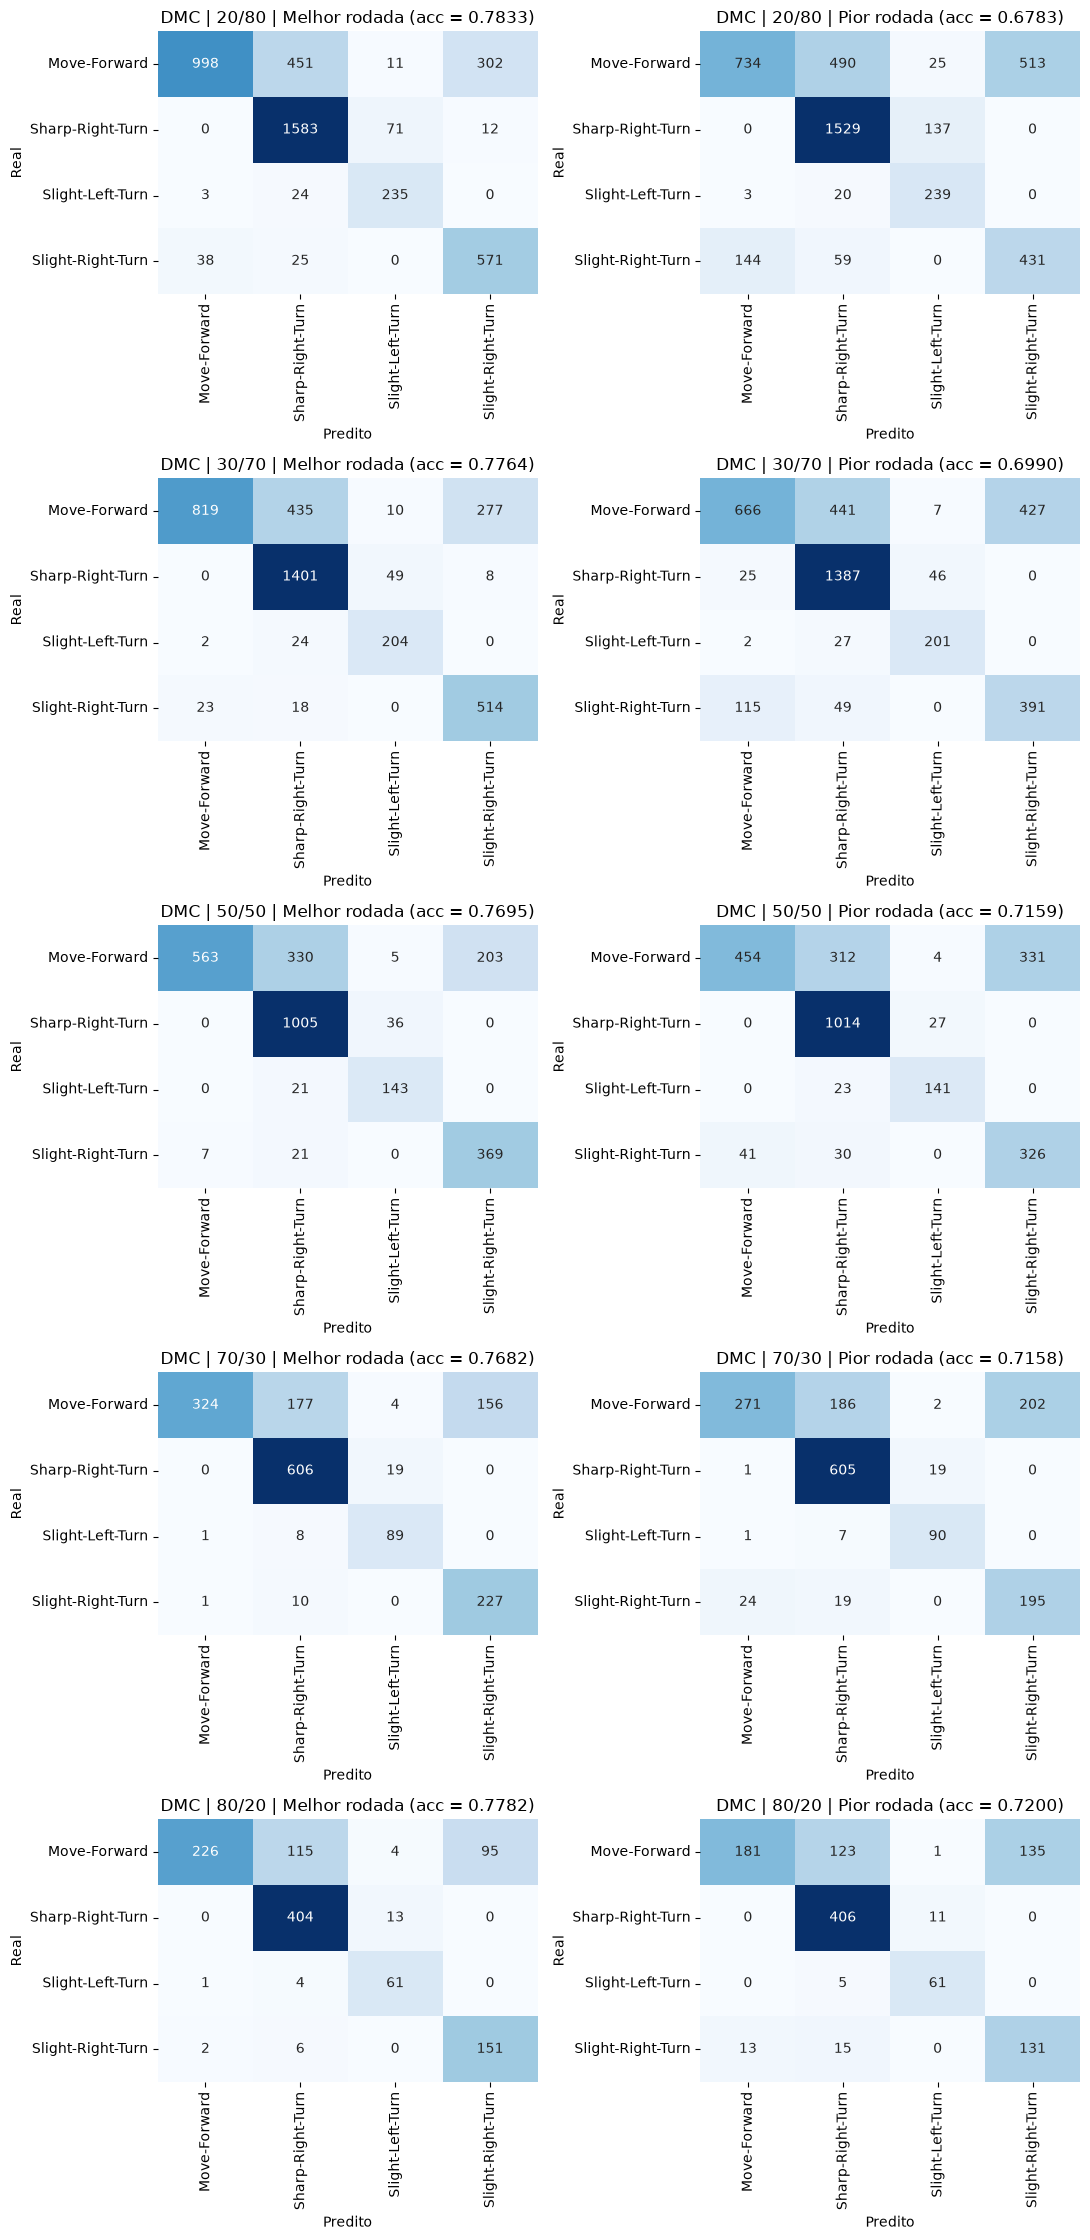

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

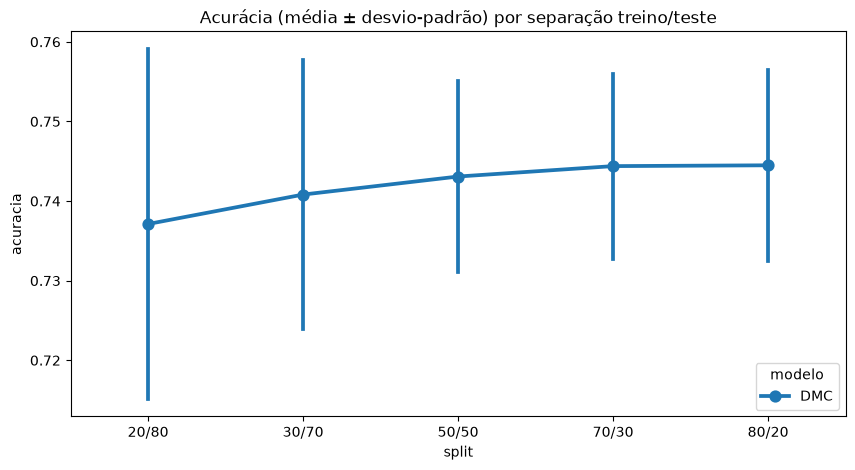

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                         
Move-Forward      20/80 DMC     0.4618  0.0331  0.5664  0.4018   0.4572
                  30/70 DMC     0.4625  0.0278  0.5490  0.4134   0.4598
                  50/50 DMC     0.4600  0.0212  0.5150  0.4124   0.4596
                  70/30 DMC     0.4603  0.0205  0.5083  0.4100   0.4599
                  80/20 DMC     0.4601  0.0226  0.5136  0.4045   0.4591
Sharp-Right-Turn  20/80 DMC     0.9551  0.0227  0.9868  0.8788   0.9625
                  30/70 DMC     0.9606  0.0162  0.9863  0.8957   0.9636
                  50/50 DMC     0.9654  0.0085  0.9798  0.9251   0.9664
                  70/30 DMC     0.9657  0.0070  0.9808  0.9440   0.9664
                  80/20 DMC     0.9670  0.0084  0.9856  0.9400   0.9688
Slight-Left-Turn  20/80 DMC     0.8889  0.0302  0.9695  0.8321   0.8855
                  30/70 DMC     0.8877  0.0278  0.9522  0.8217   0.8913
                  50/50 DMC     0.8871  0.0259  0.9329  0.8293   0.8902
                  70/30 DMC     0.8908  0.0276  0.9592  0.8265   0.8878
                  80/20 DMC     0.8900  0.0338  0.9697  0.8182   0.8939
Slight-Right-Turn 20/80 DMC     0.8668  0.0703  0.9685  0.6798   0.8888
                  30/70 DMC     0.8752  0.0609  0.9658  0.6991   0.8919
                  50/50 DMC     0.8858  0.0364  0.9496  0.7733   0.8841
                  70/30 DMC     0.8921  0.0331  0.9622  0.8193   0.8950
                  80/20 DMC     0.8875  0.0334  0.9686  0.8050   0.8868

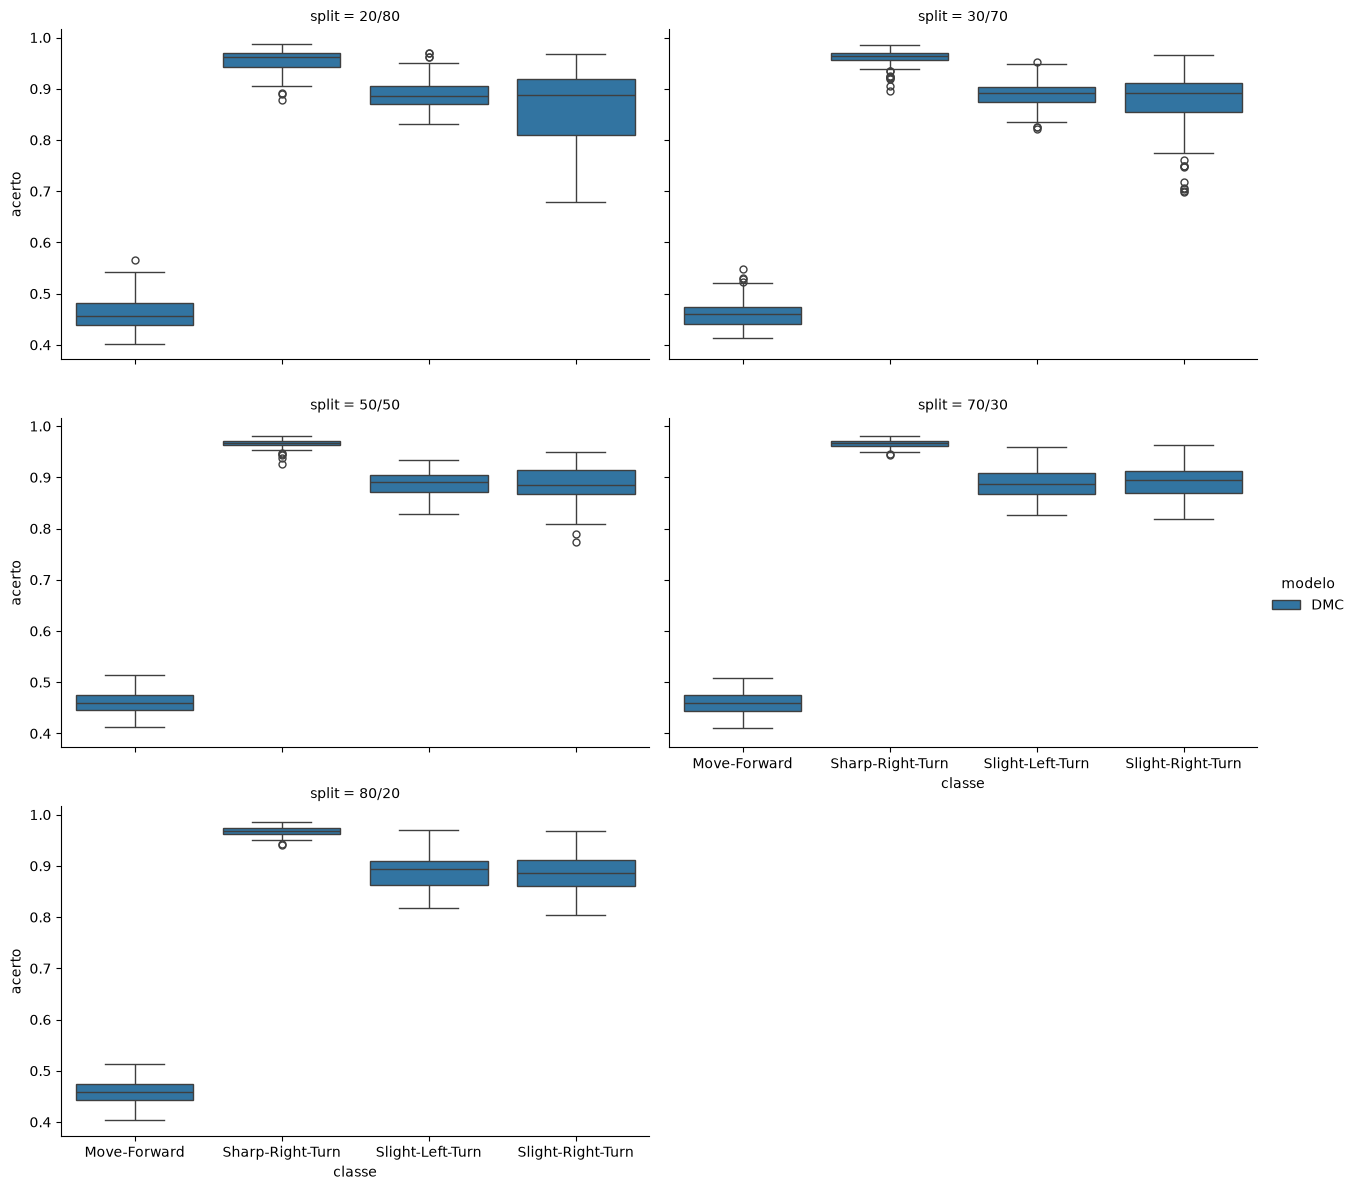

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: DMC com split 80/20 -> acurácia média 0.7445

Tempo médio por rodada (ms):
  DMC: treino 1.891 | teste 2.588

Efeito do split (acurácia média 20/80 -> 80/20):
  DMC: 0.7371 -> 0.7445 (+0.0074)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.4610
  Slight-Right-Turn: 0.8815
  Slight-Left-Turn: 0.8889
  Sharp-Right-Turn: 0.9627
Classe mais fácil: Sharp-Right-Turn | mais difícil: Move-Forward
